In [12]:
pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [13]:
pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


Outliers detected: 16624


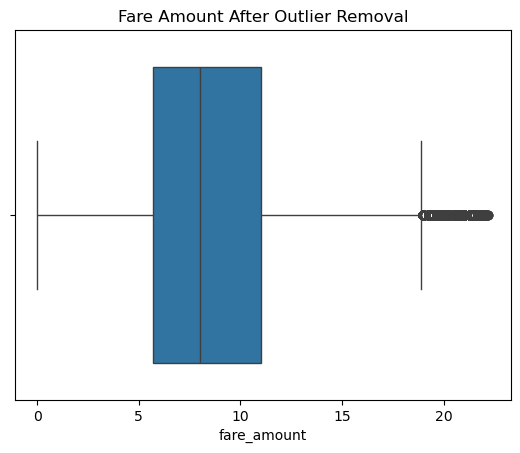

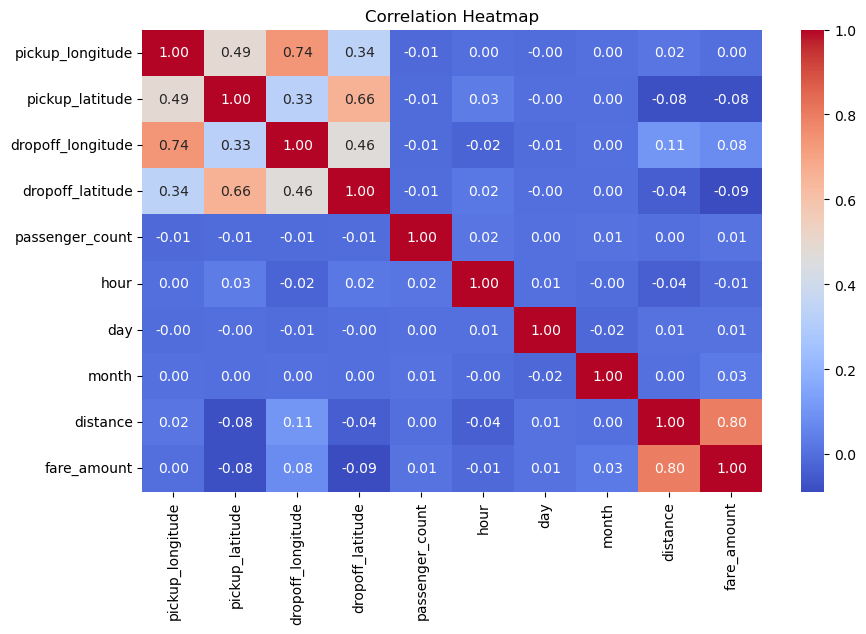


 Linear Regression
R2 Score: 0.6518
RMSE: 2.4583
MAE: 1.7249

 Random Forest Regression
R2 Score: 0.7375
RMSE: 2.1342
MAE: 1.5076

Uber Fare Prediction Completed!


In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Load dataset
df = pd.read_csv("uber.csv")

# Preprocessing
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")
df = df.dropna()

df = df[
    (df["fare_amount"] > 0) &
    (df["fare_amount"] <= 100) &
    (df["passenger_count"].between(1, 6)) &
    (df["pickup_longitude"].between(-75, -72)) &
    (df["dropoff_longitude"].between(-75, -72)) &
    (df["pickup_latitude"].between(40, 42)) &
    (df["dropoff_latitude"].between(40, 42))
].copy()

# Convert pickup time into useful features
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce"
)
df = df.dropna(subset=["pickup_datetime"])

df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month

# Calculate distance using Haversine formula
lat1 = np.radians(df["pickup_latitude"])
lat2 = np.radians(df["dropoff_latitude"])
lon1 = np.radians(df["pickup_longitude"])
lon2 = np.radians(df["dropoff_longitude"])

a = (np.sin((lat2-lat1)/2)**2 +
     np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2)

df["distance"] = 6371 * 2 * np.arcsin(np.sqrt(a))

df = df[df["distance"] <= 50].copy()

# 2. Identify and remove fare outliers using IQR
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["fare_amount"] < lower) |
    (df["fare_amount"] > upper)
]

print("Outliers detected:", len(outliers))
df = df[
    df["fare_amount"].between(lower, upper)
].copy()

# Plot outliers
sns.boxplot(x=df["fare_amount"])
plt.title("Fare Amount After Outlier Removal")
plt.show()

# 3. Check correlation
features = [
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "passenger_count", "hour", "day", "month", "distance"
]

plt.figure(figsize=(10, 6))
sns.heatmap(
    df[features + ["fare_amount"]].corr(),
    annot=True, cmap="coolwarm", fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

# 4. Prepare data and train models
X = df[features]
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

rf = RandomForestRegressor(
    n_estimators=50, random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

# 5. Evaluate and compare models
def evaluate(name, actual, predicted):
    r2 = r2_score(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)

    print("\n", name)
    print("R2 Score:", round(r2, 4))
    print("RMSE:", round(rmse, 4))
    print("MAE:", round(mae, 4))

evaluate("Linear Regression", y_test, pred_lr)
evaluate("Random Forest Regression", y_test, pred_rf)

print("\nUber Fare Prediction Completed!")
